In [1]:
'''Generate structured, comprehensive reports summarizing model findings, feature importance, and business implications,
 ensuring clarity and actionable insights for both technical and non-technical stakeholders.'''

'Generate structured, comprehensive reports summarizing model findings, feature importance, and business implications,\n ensuring clarity and actionable insights for both technical and non-technical stakeholders.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score


In [3]:
# load dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# prepare features and train model
features = ['month', 'region', 'category', 'medicine', 'age_group', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
df_encoded = pd.get_dummies(df[features], drop_first=True)
X = df_encoded
y = df['units_sold']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=30, max_depth=10, random_state=42)
model.fit(X_train.iloc[:30000], y_train.iloc[:30000])
y_pred = model.predict(X_test.iloc[:5000])


In [5]:
# compute feature importance
importances = model.feature_importances_
feature_names = X.columns
importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
importance_df = importance_df.sort_values(by='importance', ascending=False).reset_index(drop=True)
importance_df.head(10)


,feature,importance
0,stock_level,0.960984
1,month,0.016993
2,covid_flag,0.011671
3,expiry_days_remaining,0.002124
4,unit_price,0.002000
5,region_South Asia,0.001548
6,medicine_Ibuprofen,0.001012
7,category_Antipyretic,0.000326
8,region_South America,0.000295
9,region_East Asia,0.000284


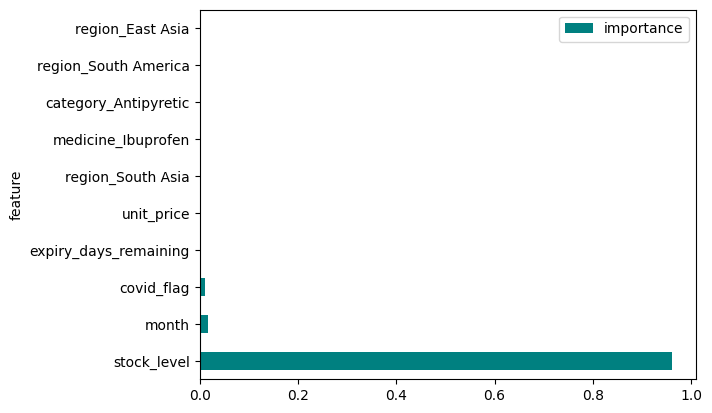

In [6]:
# plot feature importance
importance_df.head(10).plot(x='feature', y='importance', kind='barh', color='teal')
plt.show()


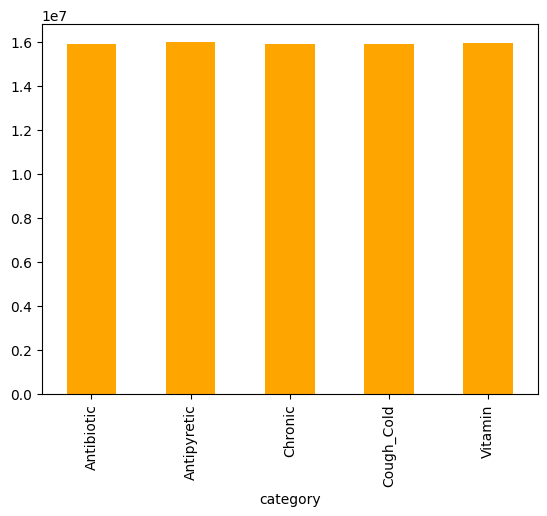

In [7]:
# plot sales by medicine category
df.groupby('category')['units_sold'].sum().plot(kind='bar', color='orange')
plt.show()


In [8]:
# analyze regional business performance
regional_summary = df.groupby('region').agg(
    total_sales=('units_sold', 'sum'),
    avg_price=('unit_price', 'mean'),
    avg_stock=('stock_level', 'mean'),
    avg_expiry_days=('expiry_days_remaining', 'mean')
).reset_index()
regional_summary


,region,total_sales,avg_price,avg_stock,avg_expiry_days
0,Africa,9879220,52.653996,4556.418138,373.818802
1,East Asia,10019811,52.632367,4550.923861,372.602559
2,Europe,9931014,52.644858,4554.858157,377.597303
3,Middle East,10001814,52.488368,4551.902596,373.004491
4,North America,9931812,52.534227,4553.444860,374.258912
5,Oceania,10001961,52.503589,4552.587234,375.620924
6,South America,9985310,52.578703,4551.757719,371.091771
7,South Asia,9973244,52.401319,4552.041927,374.312857


In [9]:
# generate technical stakeholder summary report
tech_report = {
    'model_type': type(model).__name__,
    'n_features': X_train.shape[1],
    'r2_score': round(r2_score(y_test.iloc[:5000], y_pred), 4),
    'mae': round(mean_absolute_error(y_test.iloc[:5000], y_pred), 4),
    'top_features': importance_df.head(5).to_dict(orient='records')
}
for key, value in tech_report.items():
    print(f'{key}: {value}')


model_type: RandomForestRegressor
n_features: 29
r2_score: 0.9402
mae: 64.647
top_features: [{'feature': 'stock_level', 'importance': 0.9609837573081894}, {'feature': 'month', 'importance': 0.016993454591345724}, {'feature': 'covid_flag', 'importance': 0.0116713430517548}, {'feature': 'expiry_days_remaining', 'importance': 0.002123782595881487}, {'feature': 'unit_price', 'importance': 0.002000038300706014}]


In [10]:
# generate business stakeholder recommendations report
top_category = df.groupby('category')['units_sold'].sum().idxmax()
top_region = df.groupby('region')['units_sold'].sum().idxmax()
expiring_soon = df[df['expiry_days_remaining'] < 60]['stock_level'].sum()

business_report = f"""
EXECUTIVE BUSINESS SUMMARY:
1. Top Performing Category: {top_category}
2. Top Performing Region: {top_region}
3. Inventory at Risk (Expiry < 60 days): {expiring_soon:,} units
4. Actionable Recommendation: Prioritize restocking high-velocity medicines in {top_region} and discount stock with low expiry days.
"""
print(business_report)



EXECUTIVE BUSINESS SUMMARY:
1. Top Performing Category: Antipyretic
2. Top Performing Region: East Asia
3. Inventory at Risk (Expiry < 60 days): 35,643,912 units
4. Actionable Recommendation: Prioritize restocking high-velocity medicines in East Asia and discount stock with low expiry days.

